# Komplexe Eigenwerte und Spiralpunkte

**Vertiefung zu Fall c) von Lösungsverfahren 1.9.7 und zu Satz 1.7.4 c)**

Dieses Notebook untersucht lineare Systeme $z'(t) = Az(t)$, deren Matrix **komplexe Eigenwerte** $\lambda_{1,2} = \alpha \pm i\beta$ mit $\beta \ne 0$ hat. Ihr Realteil $\alpha$ entscheidet, ob eine Bahn spiralförmig zum Ursprung läuft oder sich von ihm entfernt; der Imaginärteil $\beta$ bestimmt die Drehgeschwindigkeit.

Die Abschnitte 1 bis 4 behandeln die besonders übersichtliche **Normalform** $A = \begin{pmatrix}\alpha & -\beta\\ \beta & \alpha\end{pmatrix}$. Die Abschnitte 5 bis 8 zeigen, dass **jede** reelle $2\times 2$-Matrix mit komplexen Eigenwerten auf diese Normalform zurückgeführt werden kann, und stellen die Verbindung zu den DGL zweiter Ordnung (Abschnitt 1.7) und zum Feder-Masse-System (Beispiel 1.9.1) her.

**Voraussetzungen:** `numpy`, `sympy`, `matplotlib`, `scipy`, `ipywidgets`
**Arbeitsweise:** Zellen der Reihe nach ausführen und die Phasenporträts vergleichen.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/karkessler/dhbw-mathe3/blob/main/notebooks/differentialgleichungen/04_komplexe_eigenwerte_spiralpunkte.ipynb)

**Inhalt**

0. Physikalische Anschauung: Drehung und radiale Bewegung
1. Woher kommen komplexe Eigenwerte?
2. Reelle Lösung trotz komplexer Eigenwerte (mit Probe)
3. Phasenporträts: stabiler Spiralpunkt, instabiler Spiralpunkt, Zentrum
4. Interaktiv: Stabilität und Drehgeschwindigkeit
5. Allgemeine Matrizen: reelle Lösungen aus dem komplexen Eigenvektor (Lösungsverfahren 1.9.7 c)
6. Rückführung auf die Normalform und Drehrichtung
7. Brücke zu Abschnitt 1.7: $y'' + ay' + by = 0$ mit $D < 0$ als Spiralpunkt
8. Das Feder-Masse-System aus Beispiel 1.9.1: rein imaginäre Eigenwerte und Zentrum
9. Zusammenfassung

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import ipywidgets as widgets
from IPython.display import display, Markdown
plt.style.use('default')
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'axes.grid': True,
    'grid.color': '0.8',
    'legend.facecolor': 'white',
    'legend.edgecolor': '0.7',
})
sp.init_printing()

x, t = sp.symbols('x t', real=True)
lam = sp.symbols('lambda')


def pruefe(name, residuum):
    """Vereinfacht ein Residuum, gibt es aus und bricht ab, falls es nicht 0 ist."""
    r = sp.simplify(residuum)
    if isinstance(r, sp.MatrixBase):
        ok = all(sp.simplify(e) == 0 for e in r)
    else:
        ok = r == 0
    print(f'Probe {name}: Residuum = {r}  ->', 'ok' if ok else 'FEHLER')
    assert ok

## 0. Physikalische Anschauung: Drehung und radiale Bewegung

Betrachten wir einen Punkt mit Position $z(t) = (z_1(t), z_2(t))^T$ in einer Ebene. Für die Normalform setzt sich seine Geschwindigkeit aus zwei Anteilen zusammen:
$$z'(t) = \underbrace{\alpha\,z(t)}_{\text{radial}} + \underbrace{\beta\begin{pmatrix}-z_2(t)\\ z_1(t)\end{pmatrix}}_{\text{tangential}}.$$
Der radiale Anteil bewegt den Punkt bei $\alpha < 0$ zum Ursprung und bei $\alpha > 0$ vom Ursprung weg. Der tangentiale Anteil steht senkrecht auf $z$ und dreht den Punkt um den Ursprung (bei $\beta > 0$ gegen den Uhrzeigersinn). Zusammen entsteht eine Spirale.

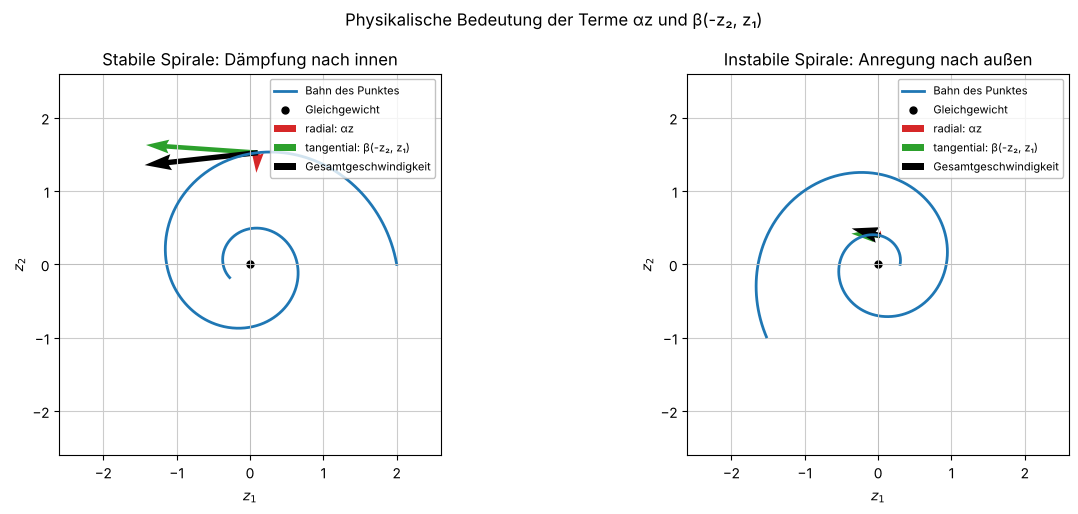

In [2]:
def zeichne_physikalische_skizze(achse, alpha_wert, titel, start_radius):
    beta_wert = 1.0
    zeit = np.linspace(0, 10, 800)
    radius = start_radius * np.exp(alpha_wert * zeit)
    x_werte = radius * np.cos(beta_wert * zeit)
    y_werte = radius * np.sin(beta_wert * zeit)

    achse.plot(x_werte, y_werte, color='#1f77b4', linewidth=2, label='Bahn des Punktes')
    achse.plot(0, 0, 'ko', ms=5, label='Gleichgewicht')

    punkt = np.array([x_werte[120], y_werte[120]])
    radial = alpha_wert * punkt
    tangential = beta_wert * np.array([-punkt[1], punkt[0]])
    gesamt = radial + tangential

    achse.quiver(*punkt, *radial, angles='xy', scale_units='xy', scale=1,
                 color='#d62728', width=0.012, label='radial: αz')
    achse.quiver(*punkt, *tangential, angles='xy', scale_units='xy', scale=1,
                 color='#2ca02c', width=0.012, label='tangential: β(-z₂, z₁)')
    achse.quiver(*punkt, *gesamt, angles='xy', scale_units='xy', scale=1,
                 color='black', width=0.014, label='Gesamtgeschwindigkeit')

    achse.axhline(0, color='0.75', lw=0.7)
    achse.axvline(0, color='0.75', lw=0.7)
    achse.set(xlim=(-2.6, 2.6), ylim=(-2.6, 2.6), aspect='equal',
              xlabel='$z_1$', ylabel='$z_2$', title=titel)
    achse.legend(loc='upper right', fontsize=8)


fig, achsen = plt.subplots(1, 2, figsize=(13, 5.2))
zeichne_physikalische_skizze(achsen[0], -0.18, 'Stabile Spirale: Dämpfung nach innen', 2.0)
zeichne_physikalische_skizze(achsen[1], 0.18, 'Instabile Spirale: Anregung nach außen', 0.3)
fig.suptitle('Physikalische Bedeutung der Terme αz und β(-z₂, z₁)')
plt.tight_layout()
plt.show()

## 1. Woher kommen komplexe Eigenwerte?

Für
$$A = \begin{pmatrix}\alpha & -\beta\\ \beta & \alpha\end{pmatrix}$$
gilt
$$\det(A - \lambda E) = (\alpha - \lambda)^2 + \beta^2.$$
Für $\beta \ne 0$ ist dieser Ausdruck für reelle $\lambda$ nie 0; die Eigenwerte sind
$$\lambda_{1,2} = \alpha \pm i\beta.$$
Der Imaginärteil $\beta$ erzeugt eine Drehung. Der Realteil $\alpha$ bestimmt gleichzeitig, ob die Amplitude abnimmt, wächst oder gleich bleibt.

**Allgemein** hat $A = \begin{pmatrix}a & b\\ c & d\end{pmatrix}$ das charakteristische Polynom $\lambda^2 - (a + d)\lambda + (ad - bc)$, also mit Spur $s = a + d$ und Determinante $\Delta = ad - bc$:
$$\lambda_{1,2} = \frac s2 \pm\sqrt{\frac{s^2}{4} - \Delta}.$$
Komplexe Eigenwerte treten genau dann auf, wenn $s^2 < 4\Delta$; dann ist $\alpha = s/2$ und $\beta = \sqrt{\Delta - s^2/4}$.

In [3]:
alpha, beta, lam = sp.symbols('alpha beta lambda', real=True)
A_symbolisch = sp.Matrix([[alpha, -beta], [beta, alpha]])
charakteristisches_polynom = sp.factor((A_symbolisch - lam * sp.eye(2)).det())

print('Charakteristisches Polynom:')
display(sp.Eq(sp.Symbol('p_lambda'), charakteristisches_polynom))
print('Eigenwerte:')
display(sp.solve(charakteristisches_polynom, lam))

A_beispiel = sp.Matrix([[-sp.Rational(1, 4), -1], [1, -sp.Rational(1, 4)]])
print('Beispielmatrix:')
display(A_beispiel)
print('Eigenwerte des Beispiels:')
display(A_beispiel.eigenvals())
assert A_beispiel.eigenvals() == {-sp.Rational(1, 4) - sp.I: 1, -sp.Rational(1, 4) + sp.I: 1}

a_, b_, c_, d_ = sp.symbols('a b c d', real=True)
A_allg = sp.Matrix([[a_, b_], [c_, d_]])
print('Allgemeines charakteristisches Polynom:')
display(sp.collect(sp.expand((A_allg - lam*sp.eye(2)).det()), lam))

Charakteristisches Polynom:


Eigenwerte:


Beispielmatrix:


⎡-1/4   -1 ⎤
⎢          ⎥
⎣ 1    -1/4⎦

Eigenwerte des Beispiels:


Allgemeines charakteristisches Polynom:


## 2. Reelle Lösung trotz komplexer Eigenwerte

Die Eigenwerte werden als Rechenhilfe über den komplexen Zahlen verwendet. Für reelle Anfangswerte bleibt die physikalische Lösung reell:
$$z(t) = e^{\alpha t}\begin{pmatrix}\cos\beta t & -\sin\beta t\\ \sin\beta t & \cos\beta t\end{pmatrix}z(0).$$
Die Matrix ist eine **Drehmatrix** um den Winkel $\beta t$; der Faktor $e^{\alpha t}$ streckt oder staucht.

* Bei $\alpha < 0$ wird der Faktor $e^{\alpha t}$ kleiner: Die Bahn spiralt **nach innen**. Der Ursprung ist asymptotisch stabil.
* Bei $\alpha > 0$ wird der Faktor größer: Die Bahn spiralt **nach außen**. Der Ursprung ist instabil.
* Bei $\alpha = 0$ bleibt die Amplitude gleich: Es entsteht ein **Zentrum** mit Kreisbahnen.

Die Größe $\beta$ bestimmt die Winkelgeschwindigkeit; eine volle Umdrehung dauert $T = 2\pi/\beta$.

**Probe:** Die Zelle prüft symbolisch, dass die Formel die DGL löst und den richtigen Anfangswert hat. Außerdem stimmt sie mit der Matrix-Exponentialfunktion $e^{At}z(0)$ überein.

In [4]:
t_s = sp.symbols('t', real=True)
z01, z02 = sp.symbols('z_01 z_02', real=True)
Z0 = sp.Matrix([z01, z02])
drehung = sp.Matrix([[sp.cos(beta*t_s), -sp.sin(beta*t_s)], [sp.sin(beta*t_s), sp.cos(beta*t_s)]])
z_formel = sp.exp(alpha*t_s)*drehung*Z0
pruefe("z' - A z", z_formel.diff(t_s) - A_symbolisch*z_formel)
pruefe('z(0) - z0', z_formel.subs(t_s, 0) - Z0)

z_exp = sp.simplify((A_beispiel*t_s).exp()*Z0)
z_bsp = z_formel.subs({alpha: -sp.Rational(1, 4), beta: 1})
pruefe('Formel = e^(At) z0 für die Beispielmatrix', sp.simplify(z_exp.rewrite(sp.cos) - z_bsp))

Probe z' - A z: Residuum = Matrix([[0], [0]])  -> ok
Probe z(0) - z0: Residuum = Matrix([[0], [0]])  -> ok


Probe Formel = e^(At) z0 für die Beispielmatrix: Residuum = Matrix([[0], [0]])  -> ok


## 3. Phasenporträts

Für dieselbe Drehgeschwindigkeit $\beta = 1$ und drei Werte von $\alpha$: Die farbigen Kurven sind Bahnen aus drei Anfangspunkten nach der Formel aus Abschnitt 2.

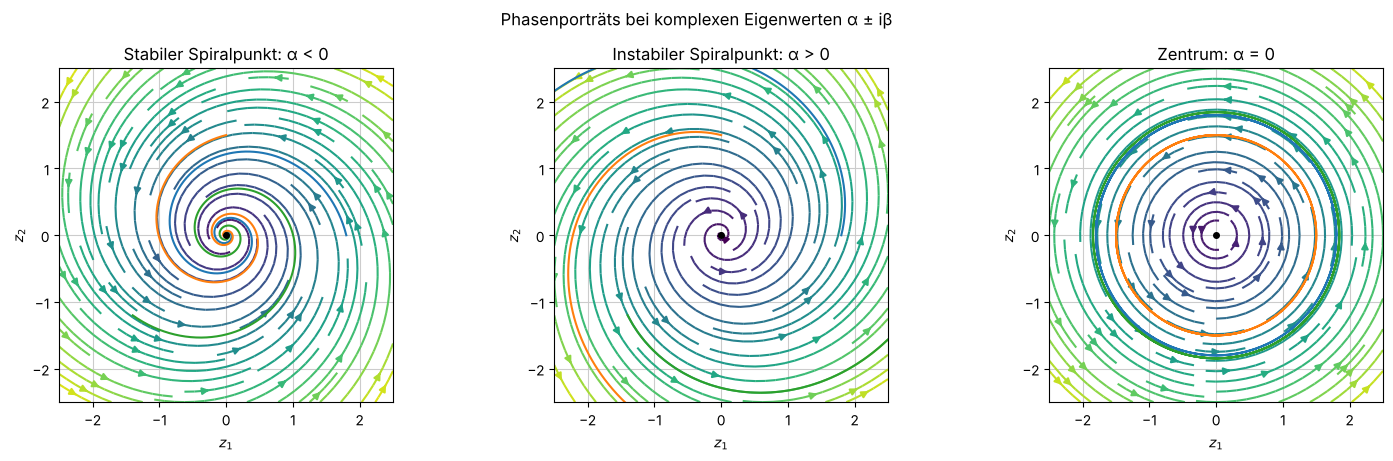

In [5]:
def loesung_spiralpunkt(alpha_wert, beta_wert, z0, zeit):
    drehung = np.array([
        [np.cos(beta_wert * zeit), -np.sin(beta_wert * zeit)],
        [np.sin(beta_wert * zeit), np.cos(beta_wert * zeit)],
    ])
    return np.exp(alpha_wert * zeit)[:, np.newaxis] * np.einsum('ijt,j->ti', drehung, z0)


faelle = [
    (-0.25, 1.0, 'Stabiler Spiralpunkt: α < 0'),
    (0.25, 1.0, 'Instabiler Spiralpunkt: α > 0'),
    (0.0, 1.0, 'Zentrum: α = 0'),
]
zeit = np.linspace(0, 16, 1_000)
fig, achsen = plt.subplots(1, 3, figsize=(15, 4.6))

for achse, (alpha_wert, beta_wert, titel) in zip(achsen, faelle):
    gitter = np.linspace(-2.5, 2.5, 25)
    X, Y = np.meshgrid(gitter, gitter)
    U = alpha_wert * X - beta_wert * Y
    V = beta_wert * X + alpha_wert * Y
    achse.streamplot(X, Y, U, V, color=np.hypot(U, V), cmap='viridis', density=1.1)

    for z0 in ([1.8, 0], [0, 1.5], [-1.4, -1.2]):
        bahn = loesung_spiralpunkt(alpha_wert, beta_wert, np.array(z0), zeit)
        achse.plot(bahn[:, 0], bahn[:, 1])

    achse.plot(0, 0, 'ko', ms=4)
    achse.set(xlim=(-2.5, 2.5), ylim=(-2.5, 2.5), aspect='equal',
              xlabel='$z_1$', ylabel='$z_2$', title=titel)

fig.suptitle('Phasenporträts bei komplexen Eigenwerten α ± iβ')
plt.tight_layout()
plt.show()

## 3. Interaktiv: Stabilität und Drehgeschwindigkeit

Ändern Sie den Realteil $\alpha$ und den Imaginärteil $\beta$ der Eigenwerte

$$\lambda_{1,2}=\alpha\pm i\beta.$$

Beobachten Sie: Das Vorzeichen von $\alpha$ entscheidet über die Stabilität; $|\beta|$ bestimmt die Drehgeschwindigkeit.

Output()

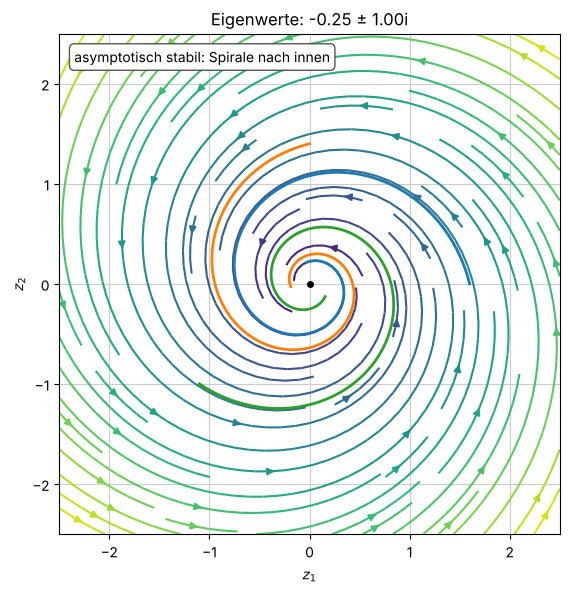

In [6]:
from IPython.display import display


def zeichne_spiralpunkt(alpha_wert=-0.25, beta_wert=1.0):
    zeit = np.linspace(0, 8, 800)
    gitter = np.linspace(-2.5, 2.5, 25)
    X, Y = np.meshgrid(gitter, gitter)
    U = alpha_wert * X - beta_wert * Y
    V = beta_wert * X + alpha_wert * Y

    if abs(alpha_wert) < 1e-9:
        klassifikation = 'stabil, nicht asymptotisch stabil: Zentrum'
    elif alpha_wert < 0:
        klassifikation = 'asymptotisch stabil: Spirale nach innen'
    else:
        klassifikation = 'instabil: Spirale nach außen'

    fig, achse = plt.subplots(figsize=(7, 6.5))
    achse.streamplot(X, Y, U, V, color=np.hypot(U, V), cmap='viridis', density=1.15)

    maximale_auslenkung = 2.5
    for z0 in ([1.6, 0], [0, 1.4], [-1.1, -1.0]):
        bahn = loesung_spiralpunkt(alpha_wert, beta_wert, np.array(z0), zeit)
        achse.plot(bahn[:, 0], bahn[:, 1], linewidth=2)
        maximale_auslenkung = max(maximale_auslenkung, 1.1 * np.max(np.abs(bahn)))

    achse.plot(0, 0, 'ko', ms=4)
    achse.set(xlim=(-maximale_auslenkung, maximale_auslenkung),
              ylim=(-maximale_auslenkung, maximale_auslenkung), aspect='equal',
              xlabel='$z_1$', ylabel='$z_2$',
              title=f'Eigenwerte: {alpha_wert:.2f} ± {beta_wert:.2f}i')
    achse.text(0.03, 0.97, klassifikation, transform=achse.transAxes, va='top',
               bbox={'boxstyle': 'round,pad=0.35', 'fc': 'white', 'alpha': 0.95, 'ec': '0.3'})
    plt.show()


alpha_regler = widgets.FloatSlider(value=-0.25, min=-0.5, max=0.5, step=0.05,
                                   description='Realteil α:', continuous_update=False)
beta_regler = widgets.FloatSlider(value=1.0, min=0.2, max=3.0, step=0.1,
                                  description='Imaginärteil β:', continuous_update=False)
steuerung = widgets.VBox([
    widgets.HTML('<b>Eigenwerte λ = α ± iβ</b>'),
    alpha_regler,
    beta_regler,
])
ausgabe = widgets.interactive_output(
    zeichne_spiralpunkt,
    {'alpha_wert': alpha_regler, 'beta_wert': beta_regler},
)
display(steuerung, ausgabe)

# Statische Vorschau für GitHub.
zeichne_spiralpunkt()

## 5. Allgemeine Matrizen: reelle Lösungen aus dem komplexen Eigenvektor

In der Praxis liegt die Matrix selten in Normalform vor. Lösungsverfahren 1.9.7 c) des Skripts sagt: Bei $\lambda_{1,2} = \alpha \pm i\beta$ erhält man mit **reellen Vektoren** $d, f$ und dem Ansatz
$$y(x) = \bigl(d\cos\beta x + f\sin\beta x\bigr)\,e^{\alpha x}$$
die Lösung der homogenen DGL. Woher kommen $d$ und $f$? Zwei gleichwertige Wege:

**Weg 1 – Real- und Imaginärteil.** Zum Eigenwert $\lambda = \alpha + i\beta$ gehört ein **komplexer** Eigenvektor $v = p + i\,q$ ($p, q$ reell). Dann ist $v\,e^{\lambda t}$ eine komplexe Lösung. Weil $A$ reell ist, sind Real- und Imaginärteil selbst Lösungen (Superpositionsprinzip, Satz 1.9.6):
$$v\,e^{\lambda t} = (p + iq)\,e^{\alpha t}(\cos\beta t + i\sin\beta t)$$
$$\Longrightarrow\quad z_1(t) = e^{\alpha t}\bigl(p\cos\beta t - q\sin\beta t\bigr),\qquad z_2(t) = e^{\alpha t}\bigl(p\sin\beta t + q\cos\beta t\bigr).$$
Die allgemeine reelle Lösung ist $z = k_1 z_1 + k_2 z_2$.

**Weg 2 – Koeffizientenvergleich** (wie in Notebook 03, Fall c): Ansatz einsetzen und die Koeffizienten von $\cos$ und $\sin$ vergleichen; $d$ ist frei, $f$ folgt daraus.

**Beispiel:** $A = \begin{pmatrix}3 & -10\\ 2 & -5\end{pmatrix}$, Spur $-2$, Determinante $-15 + 20 = 5$, also $\lambda = -1 \pm 2i$. Die Matrix ist **nicht** in Normalform; die Bahnen sind deshalb keine Kreisspiralen, sondern gestauchte, schräg liegende (elliptische) Spiralen.

In [7]:
A5 = sp.Matrix([[3, -10], [2, -5]])
lam1 = -1 + 2*sp.I
print('Eigenwerte:', list(A5.eigenvals()))
v = (A5 - lam1*sp.eye(2)).nullspace()[0]
v = sp.simplify(v/v[1])                                   # zweite Komponente auf 1 normieren
p, q = v.applyfunc(sp.re), v.applyfunc(sp.im)
display(Markdown(f'Komplexer Eigenvektor zu $\\lambda = -1 + 2i$: $v = {sp.latex(v.T)}^T$, '
                 f'$p = \\operatorname{{Re}}v = {sp.latex(p.T)}^T$, $q = \\operatorname{{Im}}v = {sp.latex(q.T)}^T$'))
pruefe('A v - λ v', A5*v - lam1*v)

al5, be5 = sp.re(lam1), sp.im(lam1)
z1 = sp.exp(al5*t_s)*(p*sp.cos(be5*t_s) - q*sp.sin(be5*t_s))
z2 = sp.exp(al5*t_s)*(p*sp.sin(be5*t_s) + q*sp.cos(be5*t_s))
display(Markdown('Reelle Lösungen (Real- und Imaginärteil von $v\\,e^{\\lambda t}$):'), z1, z2)
pruefe("z1' - A z1", z1.diff(t_s) - A5*z1)
pruefe("z2' - A z2", z2.diff(t_s) - A5*z2)
print('Wronski-Determinante W(0) =', sp.Matrix.hstack(z1, z2).subs(t_s, 0).det(), '≠ 0  -> Fundamentalsystem')

# Weg 2: Koeffizientenvergleich mit dem Ansatz aus dem Skript
d_s, f_s = sp.Matrix(sp.symbols('d1 d2')), sp.Matrix(sp.symbols('f1 f2'))
ansatz = (d_s*sp.cos(2*t_s) + f_s*sp.sin(2*t_s))*sp.exp(-t_s)
rest = sp.expand(sp.simplify((ansatz.diff(t_s) - A5*ansatz)*sp.exp(t_s)))
gls = [komp.coeff(fn) for komp in rest for fn in (sp.cos(2*t_s), sp.sin(2*t_s))]
print('Weg 2, Koeffizientenvergleich:', sp.solve(gls, list(f_s)), ' (d1, d2 frei)')

Eigenwerte: [-1 - 2*I, -1 + 2*I]


Komplexer Eigenvektor zu $\lambda = -1 + 2i$: $v = \left[\begin{matrix}2 + i & 1\end{matrix}\right]^T$, $p = \operatorname{Re}v = \left[\begin{matrix}2 & 1\end{matrix}\right]^T$, $q = \operatorname{Im}v = \left[\begin{matrix}1 & 0\end{matrix}\right]^T$

Probe A v - λ v: Residuum = Matrix([[0], [0]])  -> ok


Reelle Lösungen (Real- und Imaginärteil von $v\,e^{\lambda t}$):

⎡                          -t⎤
⎢(-sin(2⋅t) + 2⋅cos(2⋅t))⋅ℯ  ⎥
⎢                            ⎥
⎢         -t                 ⎥
⎣        ℯ  ⋅cos(2⋅t)        ⎦

⎡                         -t⎤
⎢(2⋅sin(2⋅t) + cos(2⋅t))⋅ℯ  ⎥
⎢                           ⎥
⎢        -t                 ⎥
⎣       ℯ  ⋅sin(2⋅t)        ⎦

Probe z1' - A z1: Residuum = Matrix([[0], [0]])  -> ok
Probe z2' - A z2: Residuum = Matrix([[0], [0]])  -> ok
Wronski-Determinante W(0) = -1 ≠ 0  -> Fundamentalsystem


Weg 2, Koeffizientenvergleich: {f1: 2*d1 - 5*d2, f2: d1 - 2*d2}  (d1, d2 frei)


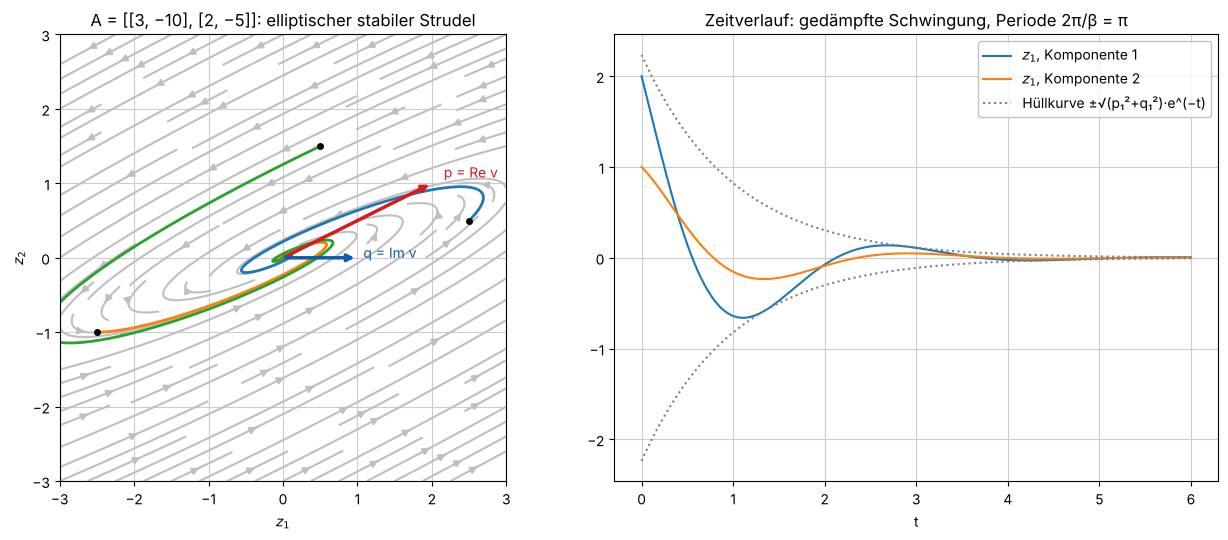

In [8]:
A5_num = np.array(A5.tolist(), dtype=float)
gitter = np.linspace(-3, 3, 25)
X, Y = np.meshgrid(gitter, gitter)
U = A5_num[0, 0]*X + A5_num[0, 1]*Y; V = A5_num[1, 0]*X + A5_num[1, 1]*Y
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
ax1.streamplot(X, Y, U, V, color='0.75', density=1.1)
ts = np.linspace(0, 6, 800)
for y0 in ([2.5, 0.5], [-2.5, -1.0], [0.5, 1.5]):
    s = solve_ivp(lambda tt, y: A5_num @ y, (0, 6), y0, t_eval=ts, rtol=1e-9)
    ax1.plot(s.y[0], s.y[1], linewidth=2); ax1.plot(*y0, 'ko', ms=4)
p_n, q_n = np.array(p, dtype=float).ravel(), np.array(q, dtype=float).ravel()
for vek, name, farbe in ((p_n, 'p = Re v', '#d71920'), (q_n, 'q = Im v', '#0b5cad')):
    ax1.annotate('', xy=vek, xytext=(0, 0), arrowprops=dict(arrowstyle='->', color=farbe, lw=2.5))
    ax1.annotate(name, vek*1.08, color=farbe)
ax1.set(xlim=(-3, 3), ylim=(-3, 3), aspect='equal', xlabel='$z_1$', ylabel='$z_2$',
        title='A = [[3, −10], [2, −5]]: elliptischer stabiler Strudel')
f1_, f2_ = sp.lambdify(t_s, z1, 'numpy'), sp.lambdify(t_s, z2, 'numpy')
w1, w2 = np.array(f1_(ts), dtype=float).reshape(2, -1), np.array(f2_(ts), dtype=float).reshape(2, -1)
ax2.plot(ts, w1[0], label='$z_1$, Komponente 1'); ax2.plot(ts, w1[1], label='$z_1$, Komponente 2')
amp = np.hypot(p_n[0], q_n[0])                            # Amplitude der 1. Komponente
ax2.plot(ts, amp*np.exp(-ts), ':', color='gray', label='Hüllkurve ±√(p₁²+q₁²)·e^(−t)'); ax2.plot(ts, -amp*np.exp(-ts), ':', color='gray')
ax2.set(xlabel='t', title='Zeitverlauf: gedämpfte Schwingung, Periode 2π/β = π'); ax2.legend()
plt.tight_layout(); plt.show()

## 6. Rückführung auf die Normalform und Drehrichtung

Aus $Av = \lambda v$ mit $v = p + iq$ und $\lambda = \alpha + i\beta$ folgt durch Trennen von Real- und Imaginärteil
$$A\,p = \alpha\,p - \beta\,q,\qquad A\,q = \beta\,p + \alpha\,q.$$
Mit der reellen Matrix $P = (p\;\;q)$ heißt das
$$A\,P = P\begin{pmatrix}\alpha & \beta\\ -\beta & \alpha\end{pmatrix}\quad\Longleftrightarrow\quad P^{-1}AP = \begin{pmatrix}\alpha & \beta\\ -\beta & \alpha\end{pmatrix}.$$
In den neuen Koordinaten $w = P^{-1}z$ gilt also $w' = \begin{pmatrix}\alpha & \beta\\ -\beta & \alpha\end{pmatrix}w$ – die Normalform aus den Abschnitten 1 bis 4 (mit $-\beta$ statt $\beta$, d. h. Drehung im Uhrzeigersinn in den $w$-Koordinaten). **Jede** reelle $2\times 2$-Matrix mit komplexen Eigenwerten ist also eine Normalform „in schiefen Koordinaten“: Die Kreisspiralen werden durch $P$ zu elliptischen Spiralen verzerrt. Stabilität ($\alpha$) und Drehgeschwindigkeit ($\beta$) bleiben dieselben. (Dass im Beispiel trotzdem gegen den Uhrzeigersinn gedreht wird, liegt an $\det P = -1$: Der Koordinatenwechsel spiegelt die Orientierung.)

**Drehrichtung im Original:** Sie lässt sich nicht an $\beta$ ablesen, weil die Eigenwerte als Paar $\alpha \pm i\beta$ auftreten. Für $A = \begin{pmatrix}a & b\\ c & d\end{pmatrix}$ zeigt die Geschwindigkeit im Punkt $(1, 0)$ in Richtung $\binom{a}{c}$. Bei $c > 0$ dreht die Bahn **gegen den Uhrzeigersinn**, bei $c < 0$ im Uhrzeigersinn. (Bei komplexen Eigenwerten ist $(a - d)^2 + 4bc < 0$, also $bc < 0$ und $c \ne 0$.) Im Beispiel ist $c = 2 > 0$: Die Bahnen drehen gegen den Uhrzeigersinn.

In [9]:
P = sp.Matrix.hstack(p, q)
N = sp.simplify(P.inv()*A5*P)
display(Markdown('$P = (p\\;\\;q)$ und $P^{-1}AP$:'), P, N)
pruefe('P^-1 A P - [[α, β], [-β, α]]', N - sp.Matrix([[al5, be5], [-be5, al5]]))
print('Drehrichtung: c =', A5[1, 0], '->', 'gegen den Uhrzeigersinn' if A5[1, 0] > 0 else 'im Uhrzeigersinn')

# numerische Kontrolle: Winkel der Bahn nimmt zu (gegen den Uhrzeigersinn)
s = solve_ivp(lambda tt, y: A5_num @ y, (0, 1), [1, 0], t_eval=np.linspace(0, 1, 50), rtol=1e-9)
winkel = np.unwrap(np.arctan2(s.y[1], s.y[0]))
print('Winkeländerung der Bahn ab (1, 0) im ersten Zeitschritt:', f'{winkel[1] - winkel[0]:+.4f} rad',
      '(positiv = gegen den Uhrzeigersinn)')

$P = (p\;\;q)$ und $P^{-1}AP$:

⎡2  1⎤
⎢    ⎥
⎣1  0⎦

⎡-1  2 ⎤
⎢      ⎥
⎣-2  -1⎦

Probe P^-1 A P - [[α, β], [-β, α]]: Residuum = Matrix([[0, 0], [0, 0]])  -> ok
Drehrichtung: c = 2 -> gegen den Uhrzeigersinn
Winkeländerung der Bahn ab (1, 0) im ersten Zeitschritt: +0.0377 rad (positiv = gegen den Uhrzeigersinn)


## 7. Brücke zu Abschnitt 1.7: $y'' + ay' + by = 0$ mit $D < 0$

Nach Bemerkung 1.9.4 wird die DGL zweiter Ordnung mit $z_1 = y$, $z_2 = y'$ zum System
$$\begin{pmatrix}y\\ y'\end{pmatrix}' = \underbrace{\begin{pmatrix}0 & 1\\ -b & -a\end{pmatrix}}_{\text{Begleitmatrix}}\begin{pmatrix}y\\ y'\end{pmatrix}.$$
Ihr charakteristisches Polynom ist $\lambda^2 + a\lambda + b$ – dasselbe wie in Satz 1.7.4. Bei $D = a^2 - 4b < 0$ hat die Begleitmatrix also die komplexen Eigenwerte $\alpha \pm i\beta$ mit $\alpha = -a/2$, $\beta = \sqrt{-D}/2$, und Fall c) von Satz 1.7.4 ($y = e^{\alpha x}(c_1\cos\beta x + c_2\sin\beta x)$) ist **genau** ein Spiralpunkt in der $(y, y')$-Ebene:

* gedämpfte Schwingung ($a > 0$) $\;\Leftrightarrow\;$ stabiler Strudel,
* ungedämpfte Schwingung ($a = 0$) $\;\Leftrightarrow\;$ Zentrum,
* angefachte Schwingung ($a < 0$) $\;\Leftrightarrow\;$ instabiler Strudel.

Wegen $c = -b < 0$ dreht die Bahn hier immer **im Uhrzeigersinn**: Ist $y > 0$, wird $y'$ kleiner. Mit den Schiebereglern sehen Sie Zeitverlauf (links) und Phasenbahn (rechts) gleichzeitig; das Beispiel $y'' + y' + 4{,}25y = 0$ aus dem Skript ist voreingestellt.

Charakteristisches Polynom der Begleitmatrix: a*lambda + b + lambda**2
Eigenwerte für a = 1, b = 17/4: [-1/2 - 2*I, -1/2 + 2*I]


Output()

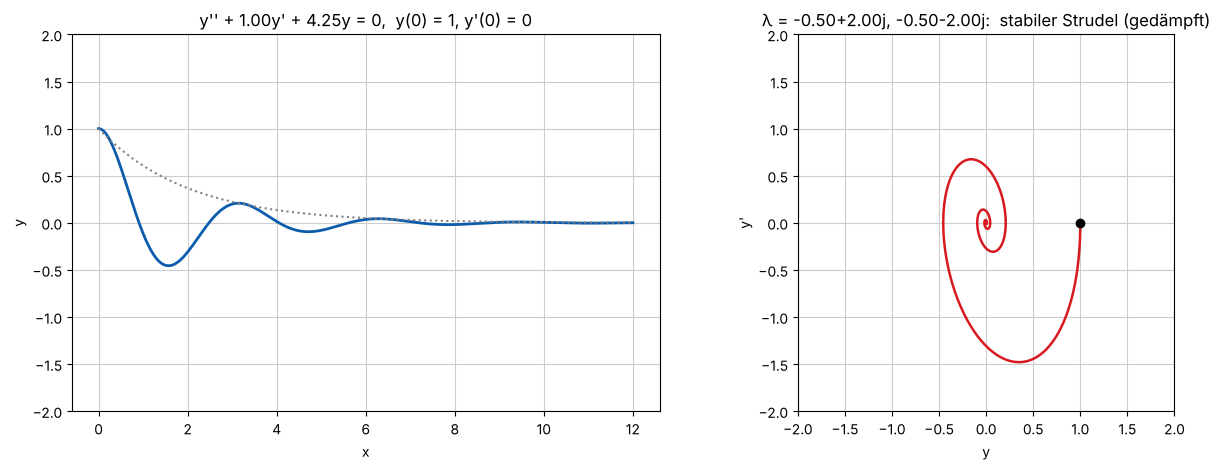

In [10]:
a_s, b_s = sp.symbols('a b', real=True)
A_begleit = sp.Matrix([[0, 1], [-b_s, -a_s]])
print('Charakteristisches Polynom der Begleitmatrix:', sp.expand((A_begleit - lam*sp.eye(2)).det()))
print('Eigenwerte für a = 1, b = 17/4:', list(A_begleit.subs({a_s: 1, b_s: sp.Rational(17, 4)}).eigenvals()))


def zeige_schwingung_als_spirale(a=1.0, b=4.25):
    M = np.array([[0.0, 1.0], [-b, -a]])
    ew = np.linalg.eigvals(M)
    ts = np.linspace(0, 12, 2000)
    s = solve_ivp(lambda tt, y: M @ y, (0, 12), [1.0, 0.0], t_eval=ts, rtol=1e-9)
    D = a**2 - 4*b
    if D >= 0:
        typ = 'D ≥ 0: keine Schwingung, Knoten'
    elif abs(a) < 1e-9:
        typ = 'Zentrum (ungedämpft)'
    else:
        typ = 'stabiler Strudel (gedämpft)' if a > 0 else 'instabiler Strudel (angefacht)'
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
    ax1.plot(ts, s.y[0], color='#0b5cad', linewidth=2)
    if D < 0:
        ax1.plot(ts, np.exp(-a/2*ts)*np.max(np.abs(s.y[0][:1])), ':', color='gray')
    ax1.set(ylim=(-2, 2), xlabel='x', ylabel='y', title=f"y'' + {a:.2f}y' + {b:.2f}y = 0,  y(0) = 1, y'(0) = 0")
    ax2.plot(s.y[0], s.y[1], color='#d71920', linewidth=1.8); ax2.plot(1, 0, 'ko')
    grenze = max(2.0, 1.1*np.max(np.abs(s.y)))
    grenze = min(grenze, 6.0)
    ax2.set(xlim=(-grenze, grenze), ylim=(-grenze, grenze), aspect='equal', xlabel='y', ylabel="y'",
            title=f'λ = {ew[0]:.2f}, {ew[1]:.2f}:  {typ}')
    plt.tight_layout(); plt.show()


regler = dict(a=widgets.FloatSlider(value=1.0, min=-0.4, max=3, step=0.05, description='a', continuous_update=False),
              b=widgets.FloatSlider(value=4.25, min=0.5, max=8, step=0.05, description='b', continuous_update=False))
display(widgets.HBox(list(regler.values())), widgets.interactive_output(zeige_schwingung_als_spirale, regler))

# Statische Vorschau für GitHub.
zeige_schwingung_als_spirale()

## 8. Das Feder-Masse-System aus Beispiel 1.9.1: rein imaginäre Eigenwerte

Das System $x'' = -\frac{D}{m}Kx$ mit $K = \begin{pmatrix}2 & -1\\ -1 & 1\end{pmatrix}$ ist ohne Dämpfung. Als System erster Ordnung für $u = (x_1, x_2, x_1', x_2')$ lautet die Matrix
$$A = \begin{pmatrix}0 & E\\ -\frac Dm K & 0\end{pmatrix}.$$
Ihre Eigenwerte sind **rein imaginär**: $\pm i\omega_1$ und $\pm i\omega_2$ mit den Eigenkreisfrequenzen $\omega_j = \sqrt{\mu_j D/m}$ aus Beispiel 1.9.1 ($\mu_j$ Eigenwerte von $K$). Es gilt also $\alpha = 0$ – in jeder Schwingungsform (Mode) liegt ein **Zentrum** vor. Startet man in einer reinen Mode, ist die Bahn in der Ebene $(x_1, x_1')$ eine geschlossene Ellipse; bei gemischtem Start überlagern sich zwei Frequenzen, und die Bahn füllt ein Gebiet aus, ohne sich zu schließen (die Frequenzen $\omega_1 \approx 0{,}618$ und $\omega_2 \approx 1{,}618$ stehen in keinem rationalen Verhältnis).

Mit einer kleinen Dämpfung $-\delta x'$ wandern alle Eigenwerte in die linke Halbebene: Aus dem Zentrum wird ein stabiler Strudel.

Eigenwerte für D/m = 1: [I*(-sqrt(5)/2 - 1/2), I*(1/2 + sqrt(5)/2), I*(1/2 - sqrt(5)/2), I*(-1/2 + sqrt(5)/2)] ≈ [-1.618033988749895j, 1.618033988749895j, -0.6180339887498949j, 0.6180339887498949j]
Eigenkreisfrequenzen sqrt(μ): [0.6180339887498949, 1.618033988749895]


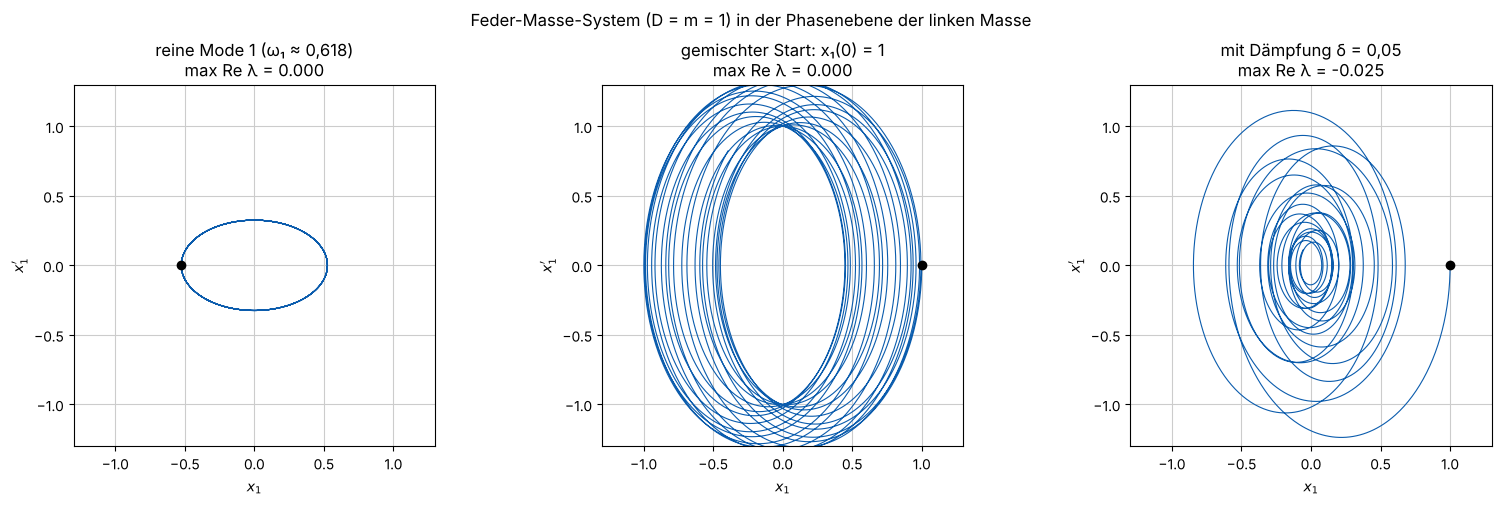

In [11]:
K = sp.Matrix([[2, -1], [-1, 1]])
Dm = sp.symbols('D_m', positive=True)                       # D/m
A_fm = sp.Matrix(sp.BlockMatrix([[sp.zeros(2), sp.eye(2)], [-Dm*K, sp.zeros(2)]]))
ews = A_fm.subs(Dm, 1).eigenvals()
print('Eigenwerte für D/m = 1:', [sp.nsimplify(e) for e in ews], '≈', [complex(sp.N(e)) for e in ews])
print('Eigenkreisfrequenzen sqrt(μ):', [float(sp.sqrt(mu)) for mu in K.eigenvals()])

K_num = np.array(K.tolist(), dtype=float)
mu, moden = np.linalg.eigh(K_num)

def fm(t, u, delta=0.0):
    return np.concatenate([u[2:], -K_num @ u[:2] - delta*u[2:]])

ts = np.linspace(0, 80, 8000)
fig, achsen = plt.subplots(1, 3, figsize=(16, 5))
starts = [(np.r_[moden[:, 0], 0, 0], 'reine Mode 1 (ω₁ ≈ 0,618)', 0.0),
          (np.r_[1.0, 0.0, 0, 0], 'gemischter Start: x₁(0) = 1', 0.0),
          (np.r_[1.0, 0.0, 0, 0], 'mit Dämpfung δ = 0,05', 0.05)]
for ax, (u0, titel, delta) in zip(achsen, starts):
    s = solve_ivp(fm, (0, 80), u0, t_eval=ts, rtol=1e-9, atol=1e-9, args=(delta,))
    ax.plot(s.y[0], s.y[2], linewidth=0.8, color='#0b5cad'); ax.plot(u0[0], u0[2], 'ko')
    ew_num = np.linalg.eigvals(np.block([[np.zeros((2, 2)), np.eye(2)], [-K_num, -delta*np.eye(2)]]))
    ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect='equal', xlabel='$x_1$', ylabel="$x_1'$",
           title=f'{titel}\nmax Re λ = {ew_num.real.max() + 0.0 if abs(ew_num.real.max()) > 1e-9 else 0.0:.3f}')
plt.suptitle('Feder-Masse-System (D = m = 1) in der Phasenebene der linken Masse'); plt.tight_layout(); plt.show()

## 9. Zusammenfassung

| Situation | Eigenwerte | reelle Lösung | Phasenporträt |
|---|---|---|---|
| Normalform $\begin{pmatrix}\alpha & -\beta\\ \beta & \alpha\end{pmatrix}$ | $\alpha \pm i\beta$ | $e^{\alpha t}R(\beta t)\,z(0)$, $R$ = Drehmatrix | Kreisspirale |
| allgemeine Matrix, $s^2 < 4\Delta$ | $\alpha = s/2$, $\beta = \sqrt{\Delta - s^2/4}$ | $e^{\alpha t}\bigl(p\cos\beta t - q\sin\beta t\bigr)$ und $e^{\alpha t}\bigl(p\sin\beta t + q\cos\beta t\bigr)$, $v = p + iq$ | elliptische Spirale, $P = (p\;q)$ verzerrt |
| $y'' + ay' + by = 0$, $D < 0$ | $-\frac a2 \pm i\frac{\sqrt{-D}}{2}$ | $e^{\alpha x}(c_1\cos\beta x + c_2\sin\beta x)$ (Satz 1.7.4 c) | Spirale in der $(y, y')$-Ebene, im Uhrzeigersinn |
| Feder-Masse ohne Dämpfung | $\pm i\omega_1,\ \pm i\omega_2$ | Überlagerung zweier Schwingungen | Zentrum je Mode |

**Merke:**

* $\alpha = \operatorname{Re}\lambda$ entscheidet über die Stabilität: $\alpha < 0$ stabil, $\alpha > 0$ instabil, $\alpha = 0$ Zentrum.
* $\beta = \lvert\operatorname{Im}\lambda\rvert$ ist die Kreisfrequenz; eine Umdrehung dauert $2\pi/\beta$.
* Die Drehrichtung liest man an der Matrix ab (Vorzeichen von $c = a_{21}$), nicht an den Eigenwerten.
* Komplexe Eigenwerte sind eine Rechenhilfe: Real- und Imaginärteil der komplexen Lösung sind reelle Lösungen.